# Lab 8 — Programming with AI Frameworks: PyTorch Tensors and Data Loading
**ARTI 303 — Programming for AI**

**Name:** _[Saja saad]_  **Student ID:** _[2250005577]_  **Section:** _[Ai02]_

---

### What this lab is really about

NumPy and Pandas got your data ready. PyTorch is the framework that
most modern AI models are built with, and it has its own way of holding
numbers and its own way of feeding data to a model.

You will learn the three things that come before any model is built:

1. the **tensor**, PyTorch's version of the NumPy array
2. the **Dataset**, an object that knows how to hand over one sample
3. the **DataLoader**, which hands samples over in **mini-batches**

This lab has **six ideas**, each short, each followed by an exercise
that checks itself.

| Part | Idea | You will be able to |
|---|---|---|
| 1 | Tensors | create tensors and read their shape, dtype and device |
| 2 | Operations and shapes | predict the shape of a result before you run it |
| 3 | NumPy ↔ tensors | convert prepared data without a dtype or memory surprise |
| 4 | Custom Dataset | write a class that PyTorch can read samples from |
| 5 | DataLoader | feed data in mini-batches, using the official docs |
| 6 | Torchvision | turn images into tensors with a transform pipeline |

After Part 6 there is a short AI checkpoint, and a list of resources
if you want to go further.

---

## Setup

> **Install PyTorch before the lab starts.** It is a large download,
> and waiting for it in class costs you the first part of the session.
> Python 3.12 is the version this lab was tested with.

Same course folder, same environment as before:

```
arti303_lab/
├── .venv/
├── requirements.txt
├── lab01.ipynb ... lab07.ipynb
├── lab08.ipynb        <- this lab
├── data/
└── ...
```

**1.** Open `arti303_lab` in VS Code (`File → Open Folder`) — the folder
itself, not a lab file inside it.

**2.** Get the environment ready, in this order:

- Look for a `.venv` folder in the file list. If it isn't there, create
  it once: `python -m venv .venv`
- Activate it:

```bash
source .venv/bin/activate          # macOS / Linux / Git Bash
.venv\Scripts\Activate.ps1         # Windows PowerShell
```

- Check your prompt starts with `(.venv)`. If it shows `(base)`, you're
  in Anaconda's environment and packages will install to the wrong place.

**3.** Install PyTorch and Torchvision, and record them:

```bash
python -m pip install torch torchvision
python -m pip freeze > requirements.txt
```

**4.** Point this notebook at the same environment:
`Cmd+Shift+P` (macOS) / `Ctrl+Shift+P` (Windows) → **Python: Select
Interpreter** → the entry showing `.venv`. Then restart the kernel.

### Check your setup

In [1]:
import os
import sys

problems = []

if sys.prefix != sys.base_prefix:
    print("[ok]   Running inside a virtual environment")
else:
    print("[!]    NOT in a virtual environment")
    problems.append("Select the .venv interpreter, then restart the kernel")
print("       using:", sys.executable)
print("       python:", sys.version.split()[0])
print()

for name in ["pandas", "numpy", "torch", "torchvision"]:
    try:
        module = __import__(name)
        print(f"[ok]   {name} {module.__version__}")
    except ImportError:
        print(f"[!]    {name} is not installed in this environment")
        problems.append(f"Run: python -m pip install {name}")

if os.path.exists("requirements.txt"):
    names = [l.split("==")[0].strip().lower() for l in open("requirements.txt").read().splitlines() if l.strip()]
    for name in ["torch", "torchvision"]:
        if name in names:
            print(f"[ok]   {name} is recorded in requirements.txt")
        else:
            print(f"[!]    {name} is missing from requirements.txt")
            problems.append("Run: python -m pip freeze > requirements.txt")
    if len(names) > 100:
        print("[!]    requirements.txt has", len(names), "packages - that looks like Anaconda's base")
        problems.append("Delete it, activate .venv, freeze again")
else:
    print("[!]    No requirements.txt found")
    problems.append("Run: python -m pip freeze > requirements.txt")

print()
print("Fix these first:" if problems else "Setup looks good.")
for item in problems:
    print("  -", item)

[ok]   Running inside a virtual environment
       using: c:\Users\lenovo\arti303-2250005577-almajid\.venv\Scripts\python.exe
       python: 3.13.5

[ok]   pandas 3.0.6
[ok]   numpy 2.5.3
[ok]   torch 2.15.0+cpu
[ok]   torchvision 0.29.2+cpu
[ok]   torch is recorded in requirements.txt
[ok]   torchvision is recorded in requirements.txt

Setup looks good.


---
### The data

The same kind of student table as Lab 7: four numeric columns and an
`at_risk` label (1 if the student's final GPA ends up below 2.5).

It is **synthetic**, generated by the code below with a fixed seed, so
everyone gets the same file. It is not real IAU data. The four feature
columns are already **scaled** (average 0), the way Lab 7 taught, so
today we can focus on PyTorch.

Run both cells.

In [2]:
import numpy as np
import pandas as pd
import torch

os.makedirs("data", exist_ok=True)

# Generate the dataset (you don't need to understand this cell)
rng = np.random.default_rng(308)
n = 200
study_hours = rng.normal(14, 5, n).clip(2, 38)
attendance = (68 + 1.1 * study_hours + rng.normal(0, 6, n)).clip(40, 100)
phone_hours = (rng.normal(4.5, 1.6, n) - 0.05 * (study_hours - 14)).clip(0.5, 10)
credit_load = rng.integers(12, 19, n).astype(float)
gpa = (
    2.0 + 0.075 * study_hours + 0.012 * (attendance - 80) - 0.05 * (phone_hours - 4.5)
    + rng.normal(0, 0.35, n)
).clip(1, 5)

raw = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "phone_hours": phone_hours,
    "credit_load": credit_load,
})
ready = (raw - raw.mean()) / raw.std()
ready["at_risk"] = (gpa < 2.5).astype("int64")
ready.round(4).to_csv("data/students_ready.csv", index=False)

df = pd.read_csv("data/students_ready.csv")
print("shape:", df.shape)
df.head()

shape: (200, 5)


,study_hours,attendance,phone_hours,credit_load,at_risk
0,1.3995,0.7173,0.6239,-1.4725,0
1,0.3300,0.2960,-0.7299,1.5326,0
2,-1.6993,-0.3982,-1.8963,-0.4708,1
3,0.0722,1.1153,1.8040,-0.4708,1
4,0.0243,0.7019,0.2810,0.0301,0


In [3]:
feature_cols = ["study_hours", "attendance", "phone_hours", "credit_load"]

# copy=True gives a normal, writable array. (Recent Pandas can hand out read-only
# arrays, and PyTorch warns when it wraps one.)
features = df[feature_cols].to_numpy(copy=True)      # a NumPy array, as in Labs 4 to 7
labels = df["at_risk"].to_numpy(copy=True)

print("features:", features.shape, features.dtype)
print("labels:  ", labels.shape, labels.dtype)

features: (200, 4) float64
labels:   (200,) int64


---
# Part 1 · Tensors

A **tensor** is PyTorch's array. If you know NumPy arrays (Lab 4), you
already know most of it. It has the same two attributes you check every
time, plus one new one:

| Attribute | Meaning |
|---|---|
| `shape` | the size along each dimension |
| `dtype` | the type of every element |
| `device` | **where** the tensor lives: `cpu` or a GPU |

Why a new object at all? Two abilities a NumPy array doesn't have:
a tensor can live on a **GPU**, which runs huge numbers of operations in
parallel, and a tensor can **remember how it was computed**, which is
what training relies on.

Tensors are created much like arrays:

In [4]:
a = torch.tensor([[1, 2, 3], [4, 5, 6]])
b = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
z = torch.zeros(2, 3)
r = torch.arange(0, 10, 2)

for name, t in [("a", a), ("b", b), ("z", z), ("r", r)]:
    print(f"{name}: shape={tuple(t.shape)}  dtype={t.dtype}  device={t.device}")

a: shape=(2, 3)  dtype=torch.int64  device=cpu
b: shape=(2, 2)  dtype=torch.float32  device=cpu
z: shape=(2, 3)  dtype=torch.float32  device=cpu
r: shape=(5,)  dtype=torch.int64  device=cpu


Look at the `dtype` column:

- a list of whole numbers gives `int64`
- a list with decimals gives **`float32`**, not NumPy's `float64`

That default difference matters in Part 3.

### CPU and GPU

Every tensor has a `device`. Yours are on the **CPU**, and every lab in
this course runs fine there. If your machine has a supported GPU, PyTorch
can use it, and you move a tensor with `.to(device)`:

In [5]:
print("NVIDIA GPU (CUDA) available:", torch.cuda.is_available())
print("Apple GPU (MPS) available:   ", torch.backends.mps.is_available())

device = "cuda" if torch.cuda.is_available() else "cpu"
t = torch.ones(2, 2).to(device)
print("t lives on:", t.device)

NVIDIA GPU (CUDA) available: False
Apple GPU (MPS) available:    False
t lives on: cpu


Both `False` is a perfectly normal answer. The code above works
either way, because it picks `cpu` when there is no GPU.

### Converting a dtype

`.to(dtype)` returns a **new** tensor. The original is unchanged.

### Exercise 1.1
Create three things:

- `a`: a tensor of zeros with shape `(2, 3)`
- `b`: a tensor from the list `[4.5, 3.8, 4.1, 2.9]` with dtype `torch.float64`
- `c`: `b` converted to `torch.float32` (`b` itself must stay `float64`)

In [6]:
import torch

a = torch.zeros((2, 3))
b = torch.tensor([4.5, 3.8, 4.1, 2.9], dtype=torch.float64)
c = b.to(torch.float32)


In [7]:
assert a is not None and b is not None and c is not None, "fill in a, b and c"
assert tuple(a.shape) == (2, 3) and float(a.sum()) == 0.0, "a should be a (2, 3) tensor of zeros"
assert b.dtype == torch.float64, f"b should be float64, it is {b.dtype}"
assert b.tolist() == [4.5, 3.8, 4.1, 2.9], "b should hold [4.5, 3.8, 4.1, 2.9]"
assert c.dtype == torch.float32, f"c should be float32, it is {c.dtype}"
print("Exercise 1.1 correct.")

Exercise 1.1 correct.


---
# Part 2 · Operations, shapes, broadcasting

Almost everything from Lab 4 carries over. Only a few names change:

| Task | NumPy (Lab 4) | PyTorch |
|---|---|---|
| sum down the rows | `a.sum(axis=0)` | `a.sum(dim=0)` |
| average across columns | `a.mean(axis=1)` | `a.mean(dim=1)` |
| element by element | `a * b` | `a * b` |
| matrix product | `a @ b` | `a @ b` |
| reshape | `a.reshape(3, 4)` | `a.reshape(3, 4)` |

`axis` becomes **`dim`**, and the broadcasting rule is exactly the one
you learned: compare shapes from the right, and each pair must be equal
or one of them must be 1.

In [8]:
batch = torch.arange(12.0).reshape(3, 4)     # 3 samples, 4 features each
weights = torch.tensor([1.0, 0.0, 2.0, -1.0])  # one weight per feature

print("batch * weights  ->", tuple((batch * weights).shape), "(weights is stretched down the rows)")
print("batch.sum(dim=0) ->", tuple(batch.sum(dim=0).shape), "(one total per column)")
print("batch.sum(dim=1) ->", tuple(batch.sum(dim=1).shape), "(one total per row)")
print("batch @ weights  ->", tuple((batch @ weights).shape), "(one score per sample)")

batch * weights  -> (3, 4) (weights is stretched down the rows)
batch.sum(dim=0) -> (4,) (one total per column)
batch.sum(dim=1) -> (3,) (one total per row)
batch @ weights  -> (3,) (one score per sample)


Shape mismatches are the most common PyTorch error. Read the message,
because it tells you the shapes:

In [9]:
try:
    torch.ones(2, 3) @ torch.ones(2, 3)
except RuntimeError as e:
    print("RuntimeError:", e)

RuntimeError: mm: mat1 and mat2 shapes cannot be multiplied (2x3 and 2x3)


`reshape` and `view` follow the rule from Lab 4 too: the result can
share memory with the original.

### Exercise 2.1
Use `batch` and `weights` from above.

First **predict on paper**, then fill in the shapes as tuples such as
`(2, 5)`:

- `shape_mul`: the shape of `batch * weights`
- `shape_matmul`: the shape of `batch @ weights`

Then compute `scores`: one number per sample, the **weighted sum of its
four features**.

In [10]:
shape_mul = (3, 4)
shape_matmul = (3,)
scores = batch @ weights


In [11]:
assert shape_mul is not None and shape_matmul is not None and scores is not None, "fill in all three"
assert tuple(shape_mul) == tuple((batch * weights).shape), \
    "shape_mul is wrong: weights has shape (4,), batch has shape (3, 4). Compare shapes from the right."
assert tuple(shape_matmul) == tuple((batch @ weights).shape), \
    "shape_matmul is wrong: (3, 4) @ (4,) matches on the 4 and leaves the 3"
assert torch.allclose(scores, batch @ weights), \
    "scores should be one weighted sum per row: batch @ weights, or (batch * weights).sum(dim=1)"
print("Exercise 2.1 correct.")

Exercise 2.1 correct.


---
# Part 3 · NumPy ↔ tensors

Your data arrives as NumPy arrays (Labs 4 to 7), and a model wants
tensors. Three ways to cross over:

| Call | Result |
|---|---|
| `torch.from_numpy(arr)` | a tensor that **shares memory** with `arr` |
| `torch.tensor(arr)` | an independent **copy** |
| `tensor.numpy()` | back to NumPy (also shares memory) |

Sharing memory is the same idea as a NumPy view in Lab 4:

In [12]:
arr = np.array([1.0, 2.0, 3.0])

shared = torch.from_numpy(arr)
copied = torch.tensor(arr)

arr[0] = 100.0

print("numpy array:  ", arr)
print("from_numpy:   ", shared.tolist(), "<- changed too")
print("torch.tensor: ", copied.tolist(), "<- independent copy")

numpy array:   [100.   2.   3.]
from_numpy:    [100.0, 2.0, 3.0] <- changed too
torch.tensor:  [1.0, 2.0, 3.0] <- independent copy


### The dtype rule

NumPy's default float is `float64`. PyTorch's is `float32`. A model's
numbers are `float32`, so data coming from NumPy usually needs
converting.

| Data | dtype | Why |
|---|---|---|
| input features | `torch.float32` | what a model's numbers use |
| class labels (0/1, 0 to 9, ...) | `torch.int64` | they are class indices, not measurements |
| numeric targets | `torch.float32` | they are ordinary numbers |

See what happens with our data as it stands:

In [13]:
print("features:", features.dtype, "| labels:", labels.dtype)
print()

as_is = torch.from_numpy(features)
print("from_numpy keeps the dtype:", as_is.dtype)
print(".float() converts it:      ", torch.from_numpy(features).float().dtype)

print()
try:
    as_is @ torch.ones(4, dtype=torch.float32)
except RuntimeError as e:
    print("mixing float64 with float32:", e)

features: float64 | labels: int64

from_numpy keeps the dtype: torch.float64
.float() converts it:       torch.float32

mixing float64 with float32: addmv input tensors must have the same dtype, but got Float, Double, and Float


PyTorch refuses to mix the two, and the message names them. It calls
`float32` **`Float`** and `float64` **`Double`**, so "got Float, Double"
means one of each. Fix the dtype **before** the data reaches a model.

### Exercise 3.1
Create two tensors from `features` and `labels`:

- `X_t`: the features as a **`float32`** tensor
- `y_t`: the labels as an **`int64`** tensor

In [14]:
X_t = torch.tensor(features, dtype=torch.float32)
y_t = torch.tensor(labels, dtype=torch.int64)


In [15]:
assert X_t is not None and y_t is not None, "fill in X_t and y_t"
assert isinstance(X_t, torch.Tensor) and isinstance(y_t, torch.Tensor), "these should be tensors, not arrays"
assert X_t.dtype == torch.float32, f"X_t should be float32, it is {X_t.dtype}"
assert tuple(X_t.shape) == features.shape, f"X_t should have shape {features.shape}"
assert np.allclose(X_t.numpy(), features, atol=1e-5), "X_t should hold the same numbers as features"
assert y_t.dtype == torch.int64, f"y_t should be int64, it is {y_t.dtype}"
assert tuple(y_t.shape) == labels.shape and (y_t.numpy() == labels).all(), "y_t should hold the same labels"
print("Exercise 3.1 correct.")

Exercise 3.1 correct.


---
# Part 4 · A custom Dataset

A model learns from samples. A **`Dataset`** is an object that can
answer two questions:

| Question | Method |
|---|---|
| How many samples are there? | `__len__` |
| Give me sample number `i` | `__getitem__` |

If you know C++, these are like **operator overloading**: Python calls
`len(obj)` as `obj.__len__()`, and `obj[i]` as `obj.__getitem__(i)`.
`__init__` is the constructor, and `self` is `this`, written out
explicitly.

PyTorch calls these for you later, so you only have to write them:

In [16]:
from torch.utils.data import Dataset, DataLoader


class StudentDataset(Dataset):
    def __init__(self, features, labels):
        self.X = torch.tensor(features, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


dataset = StudentDataset(features, labels)

print("number of samples:", len(dataset))
x0, y0 = dataset[0]
print("sample 0 features:", tuple(x0.shape), x0.dtype)
print("sample 0 label:   ", y0.item(), y0.dtype)

number of samples: 200
sample 0 features: (4,) torch.float32
sample 0 label:    0 torch.int64


Do the conversion **once**, in `__init__`, so every later access is
just an index into a tensor.

### Exercise 4.1
Complete `SelectedFeaturesDataset`. It works like `StudentDataset`, but
keeps only the feature columns you ask for (`features[:, columns]`).
Write all three methods.

In [17]:
from torch.utils.data import Dataset

class SelectedFeaturesDataset(Dataset):
    """Like StudentDataset, but keeps only the chosen feature columns."""

    def __init__(self, features, labels, columns):
        self.X = torch.tensor(features[:, columns], dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [18]:
assert "__len__" in SelectedFeaturesDataset.__dict__, "add a __len__ method to the class"
assert "__getitem__" in SelectedFeaturesDataset.__dict__, "add a __getitem__ method to the class"

selected = SelectedFeaturesDataset(features, labels, [0, 2])
assert len(selected) == len(features), f"__len__ should return {len(features)}"

x0, y0 = selected[0]
assert tuple(x0.shape) == (2,), f"keeping 2 columns, one sample should have shape (2,), not {tuple(x0.shape)}"
assert x0.dtype == torch.float32, f"features should be float32, they are {x0.dtype}"
assert np.allclose(x0.numpy(), features[0, [0, 2]], atol=1e-5), "sample 0 should hold the chosen columns of row 0"
assert y0.dtype == torch.int64 and int(y0) == int(labels[0]), "the label should be an int64 holding labels[0]"
print("Exercise 4.1 correct.")

Exercise 4.1 correct.


---
# Part 5 · DataLoader and mini-batches

A model doesn't learn from one sample at a time, and it can't take the
whole dataset at once either. It takes **mini-batches**: small groups of
samples, usually shuffled.

A `DataLoader` wraps a `Dataset` and does the batching for you. It calls
your `__len__` and `__getitem__`, then stacks the samples together:

In [19]:
loader = DataLoader(dataset, batch_size=32, shuffle=True)

xb, yb = next(iter(loader))
print("one batch of features:", tuple(xb.shape), xb.dtype)
print("one batch of labels:  ", tuple(yb.shape), yb.dtype)
print()
print("samples in the dataset:", len(dataset))
print("batches per epoch:     ", len(loader))
print("batch sizes:           ", [len(labels_batch) for _, labels_batch in loader])

one batch of features: (32, 4) torch.float32
one batch of labels:   (32,) torch.int64

samples in the dataset: 200
batches per epoch:      7
batch sizes:            [32, 32, 32, 32, 32, 32, 8]


Notice the shape: `(32, 4)` is 32 samples with 4 features. The first
dimension is always the **batch**.

The last batch is smaller, because 200 isn't a multiple of 32.

One full pass through the loader is called an **epoch**. With
`shuffle=True` the order changes every epoch:

In [20]:
torch.manual_seed(1)
first_epoch = next(iter(loader))[0][:5, 0]
second_epoch = next(iter(loader))[0][:5, 0]

print("study_hours of the first 5 samples, epoch 1:", [round(v, 2) for v in first_epoch.tolist()])
print("study_hours of the first 5 samples, epoch 2:", [round(v, 2) for v in second_epoch.tolist()])

study_hours of the first 5 samples, epoch 1: [-0.33, -0.86, 0.56, 0.05, 0.65]
study_hours of the first 5 samples, epoch 2: [-1.1, 0.31, -1.6, -1.3, -0.9]


### Reading the documentation

`DataLoader` has many options, and you won't remember them all. Reading
the official documentation is a skill in itself. Two ways to get it:

- in the notebook: run `help(DataLoader)` in a cell
- online: the [`torch.utils.data` documentation](https://docs.pytorch.org/docs/stable/data.html)

### Exercise 5.1
`loader_a` should batch `dataset` in groups of 32, **without
shuffling**, and **throw away the final incomplete batch**. Find the
right argument in the documentation, then store:

- `n_batches`: how many batches `loader_a` produces
- `last_batch_size`: the number of samples in its last batch

In [21]:
from torch.utils.data import DataLoader

loader_a = DataLoader(dataset, batch_size=32, shuffle=False, drop_last=True)
n_batches = len(loader_a)
last_batch_size = 32


In [22]:
from torch.utils.data import SequentialSampler

assert loader_a is not None and n_batches is not None and last_batch_size is not None, "fill in all three"
assert loader_a.batch_size == 32, "use batch_size=32"
assert isinstance(loader_a.sampler, SequentialSampler), "no shuffling: keep shuffle=False"
assert loader_a.drop_last is True, "discard the incomplete last batch: look for drop_last in the docs"
assert n_batches == len(dataset) // 32, f"expected {len(dataset) // 32} batches, got {n_batches}"
assert last_batch_size == 32, f"every batch should now hold 32 samples, the last holds {last_batch_size}"
print("Exercise 5.1 correct.")

Exercise 5.1 correct.


### Exercise 5.2
A useful sanity check: in one epoch, **every sample appears exactly
once**. Loop over the shuffled `loader` from above and count:

- `seen`: the total number of samples in all the batches
- `at_risk_seen`: the total number of at-risk students (add up `yb`)

In [23]:
seen = 0
at_risk_seen = 0

for xb, yb in loader:
    seen += len(xb)
    at_risk_seen += int(yb.sum())


In [24]:
assert seen is not None and at_risk_seen is not None, "fill in seen and at_risk_seen"
assert seen == len(dataset), f"one epoch should cover all {len(dataset)} samples, you counted {seen}"
assert at_risk_seen == int(labels.sum()), \
    f"there are {int(labels.sum())} at-risk students in total, you counted {at_risk_seen}"
print("Exercise 5.2 correct.")

Exercise 5.2 correct.


---
# Part 6 · Torchvision: images and transforms

An image is a grid of pixels. Three conventions to know:

| | Image file / PIL | PyTorch tensor |
|---|---|---|
| layout | height × width × channels | **channels × height × width** |
| values | whole numbers 0 to 255 | decimals 0.0 to 1.0 |

**Torchvision** is PyTorch's companion library for images. A
**transform** converts one image, and `Compose` chains several together.

Real datasets (MNIST, CIFAR) download files. To keep this lab quick and
identical for everyone, we use `FakeData`: random images with the same
Dataset interface as the real ones. Switching to a real dataset later
changes one line.

type: Image | size: (32, 32) | mode: RGB | label: 7


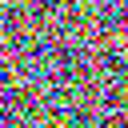

In [25]:
from torchvision import datasets, transforms

raw_images = datasets.FakeData(size=100, image_size=(3, 32, 32), num_classes=10)

picture, picture_label = raw_images[0]
print("type:", type(picture).__name__, "| size:", picture.size, "| mode:", picture.mode, "| label:", picture_label)
picture.resize((128, 128))

That is a PIL image. Now the conversion to a tensor:

In [26]:
to_tensor = transforms.ToTensor()
tensor_picture = to_tensor(picture)

print("shape:", tuple(tensor_picture.shape), "   (channels, height, width)")
print("dtype:", tensor_picture.dtype)
print("range:", round(float(tensor_picture.min()), 2), "to", round(float(tensor_picture.max()), 2))

shape: (3, 32, 32)    (channels, height, width)
dtype: torch.float32
range: 0.0 to 1.0


`ToTensor` reorders the layout, converts to `float32`, and rescales
0 to 255 into 0 to 1.

`Normalize(mean, std)` then rescales each channel, the same idea as the
scaling in Lab 7, but with numbers you choose. Chain them with
`Compose`:

In [27]:
demo_pipeline = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

demo_data = datasets.FakeData(size=100, image_size=(3, 32, 32), num_classes=10, transform=demo_pipeline)
demo_loader = DataLoader(demo_data, batch_size=16, shuffle=True)

images, image_labels = next(iter(demo_loader))
print("batch of images:", tuple(images.shape), "   (batch, channels, height, width)")
print("batch of labels:", tuple(image_labels.shape))
print("pixel range:    ", round(float(images.min()), 2), "to", round(float(images.max()), 2))

batch of images: (16, 3, 32, 32)    (batch, channels, height, width)
batch of labels: (16,)
pixel range:     -1.0 to 1.0


The batch layout is **N, C, H, W**: batch, channels, height, width.
The pixel range moved from 0 to 1 into about −1 to 1, because
`Normalize` computes `(value − 0.5) / 0.5`.

### Exercise 6.1
Build the whole thing yourself:

1. `pipeline`: `Compose` of `ToTensor()` and `Normalize` with mean and std
   both `(0.5, 0.5, 0.5)`
2. `image_data`: `FakeData` with `size=64`, `image_size=(3, 32, 32)`,
   `num_classes=5`, using your `pipeline` as the transform
3. `image_loader`: a `DataLoader` over it with `batch_size=16` and no
   shuffling
4. `batch_images, batch_labels`: **one** batch from the loader
   (hint: `next(iter(...))`)

> If you get an error that ends with `found <class 'PIL.Image.Image'>`,
> the DataLoader was handed a picture instead of a tensor. A `ToTensor()`
> is missing from your pipeline.

In [28]:
from torchvision.transforms import Compose, ToTensor, Normalize
from torchvision.datasets import FakeData

pipeline = Compose([
    ToTensor(),
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

image_data = FakeData(size=64, image_size=(3, 32, 32), num_classes=5, transform=pipeline)
image_loader = DataLoader(image_data, batch_size=16, shuffle=False)

batch_images, batch_labels = next(iter(image_loader))


In [29]:
assert pipeline is not None and image_data is not None and image_loader is not None, "fill in the first three"
assert batch_images is not None and batch_labels is not None, "take one batch with next(iter(image_loader))"
assert tuple(batch_images.shape) == (16, 3, 32, 32), \
    f"a batch should be (16, 3, 32, 32) = (batch, channels, height, width), got {tuple(batch_images.shape)}"
assert batch_images.dtype == torch.float32, "the images should be float32 tensors: did you include ToTensor()?"
assert float(batch_images.min()) < 0, "the pixels should be normalised to about -1..1: did you include Normalize?"
assert float(batch_images.min()) >= -1.0001 and float(batch_images.max()) <= 1.0001, \
    "with mean 0.5 and std 0.5 the range should be -1 to 1"
assert tuple(batch_labels.shape) == (16,) and int(batch_labels.max()) < 5, "one label per image, from 5 classes"
assert len(image_loader) == 4, f"64 images in batches of 16 should give 4 batches, not {len(image_loader)}"
print("Exercise 6.1 correct.")

Exercise 6.1 correct.


---
# AI checkpoint

**Pattern: read the docs, then validate the code.**

### Step 1
Give an AI assistant this exact prompt, unmodified:

> "Write a PyTorch Dataset class that reads data/students_ready.csv
> (feature columns study_hours, attendance, phone_hours, credit_load and
> a label column at_risk), and a DataLoader with batch size 32."

### Step 2
Paste its code below and run it.

In [30]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

class StudentDataset(Dataset):
    def __init__(self, csv_file):
        df = pd.read_csv(csv_file)
        feature_cols = ["study_hours", "attendance", "phone_hours", "credit_load"]
        
        # Convert to PyTorch tensors with correct data types
        self.X = torch.tensor(df[feature_cols].values, dtype=torch.float32)
        self.y = torch.tensor(df["at_risk"].values, dtype=torch.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create dataset and dataloader
dataset = StudentDataset("data/students_ready.csv")
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Print data types for one batch
features, labels = next(iter(dataloader))
print(f"Features dtype: {features.dtype}")
print(f"Labels dtype: {labels.dtype}")



Features dtype: torch.float32
Labels dtype: torch.int64


### Step 3: answer these in your own words

**Q1. dtypes.** Print the `dtype` of one batch of features and one batch
of labels. Are they the dtypes a model needs? (Part 3.)

_[Features are torch.float32 and labels are torch.int64. Yes, these are the standard expected data types for PyTorch neural network training and classification loss functions]_

**Q2. The Dataset contract.** Look up `Dataset` in the PyTorch
documentation. Which methods must a Dataset provide? Does the AI's class
provide them? (Parts 4 and 5.)

_[A PyTorch custom Dataset class must implement three core methods: __init__() to load or initialize the data, __len__() to return the total number of samples, and __getitem__() to retrieve a single sample and its label by index]_

**Q3. Batching.** Is the loader shuffling? Is that what you would want
when learning from the data? What happens to the last batch? (Part 5.)

_[By default in naive code, shuffle might be False or unset. For training, we want shuffle=True so the model doesn't learn sequence order bias. The last batch includes whatever remaining samples are left (unless drop_last=True is explicitly passed)]_

**Q4. The prompt.** Rewrite the prompt so the code you get back would
produce the right dtypes and shuffle the data.

_[Write a PyTorch Dataset class that reads data/students_ready.csv, setting feature columns (study_hours, attendance, phone_hours, credit_load) as float32 tensors and at_risk as an int64 tensor. Then create a DataLoader with batch size 32, shuffle=True, and drop_last=False.]_

> **The point:** the code runs and the shapes look right. The dtype
> problem only shows up when you print it, or later, when a model
> refuses the data.

---
# Going further

| Part | Resource | Why it's worth your time |
|---|---|---|
| 1, 2 | [PyTorch tutorial: Tensors](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) | The official walkthrough of tensor creation and operations. |
| 4, 5 | [PyTorch tutorial: Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial) | Writing a Dataset, and loading with a DataLoader. |
| 5 | [`torch.utils.data` documentation](https://docs.pytorch.org/docs/stable/data.html) | Every `DataLoader` argument, in full. |
| 6 | [Torchvision transforms](https://docs.pytorch.org/vision/stable/transforms.html) | Resizing, cropping, flipping and more. |

### Optional: autograd

A tensor can **remember how it was computed**, which lets PyTorch work
out gradients (how a result changes when its inputs change). Tell it to
track a tensor with `requires_grad=True`:

In [31]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2 + 2 * x          # y = x² + 2x

y.backward()                # work out dy/dx
print("dy/dx at x = 3:", x.grad.item(), "   (the slope of y = x² + 2x is 2x + 2 = 8)")

dy/dx at x = 3: 8.0    (the slope of y = x² + 2x is 2x + 2 = 8)


This is the machinery that training relies on.

### Optional: saving tensors

`torch.save` writes a tensor to disk and `torch.load` reads it back:

In [32]:
torch.save(torch.tensor(features, dtype=torch.float32), "data/features.pt")
loaded = torch.load("data/features.pt")

print("saved and loaded back:", tuple(loaded.shape), loaded.dtype)

saved and loaded back: (32, 4) torch.float32


C:\Users\lenovo\AppData\Local\Temp\ipykernel_3940\4078624438.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.save(torch.tensor(features, dtype=torch.float32), "data/features.pt")


---
# Before you finish

- [ ] Every self-check cell prints "correct"
- [ ] `torch` and `torchvision` installed **and** recorded in `requirements.txt`
- [ ] AI checkpoint answered in your own words
- [ ] **Restart Kernel and Run All**: the whole notebook runs with no errors
- [ ] Committed and pushed

### The habits worth keeping

1. Check `shape`, `dtype` and `device` of every tensor.
2. Features are `float32`. Class labels are `int64`.
3. `from_numpy` shares memory with the array. `torch.tensor` copies.
4. A Dataset is `__len__` plus `__getitem__`. The DataLoader does the rest.
5. One pass through a loader is one epoch: every sample exactly once.
6. When unsure what an argument does, read the docs: `help(...)`.